In [240]:
print('In the name of Allah')

In the name of Allah


In [241]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Mandatory

Problem 1: Z-Score Method (Normal Data)

Dataset (Age of students in a class):

[18, 19, 20, 20, 21, 21, 22, 22, 23, 24, 25, 26, 27, 28, 30, 32, 35, 40, 45, 70]


Tasks:

Calculate the mean and standard deviation of Age.

Compute Z-Score for each value.

Identify outliers using |Z| > 3 conditions.

Remove those outliers and show the new dataset length.

In [242]:
df = pd.DataFrame( {'Age' : [18, 19, 20, 20, 21, 21, 22, 22, 23, 24, 25, 26, 27, 28, 30, 32, 35, 40, 45, 70] } )

df.size

age_mean = df['Age'].mean()

print(f'Mean of Age : {age_mean}')

std_age = df['Age'].std()

print(f'Std of Age : {std_age}')

# Computing Z-Score

df['zscore_age'] = ( df['Age'] - age_mean ) / std_age

df

outlier_age = df[abs( df['zscore_age'] ) > 3]

# print(len(outlier_age))
# display(outlier_age)

df = df[abs( df['zscore_age'] ) <= 3]

# len(df)
df

print(f'Length of New Dataset : {len(df)}')

Mean of Age : 28.4
Std of Age : 12.132600710482482
Length of New Dataset : 19


Problem 2: IQR Method (Skewed Data)

Dataset (Monthly salaries in thousand BDT):

[25, 28, 30, 32, 32, 33, 35, 35, 36, 38, 40, 42, 45, 48, 50, 55, 60, 65, 70, 80, 120, 150, 200, 250, 500]


Tasks:

Calculate Q1 (25th percentile) and Q3 (75th percentile).

Find IQR = Q3 - Q1.

Calculate lower bound and upper bound.

Identify outliers.

Cap (clip) the outliers to the bounds instead of deleting them.

Show min and max after capping.


In [243]:
df = pd.DataFrame(
    { 'salary' : [ 25, 28, 30, 32, 32, 33, 35, 35, 36, 38, 40, 42, 45, 48, 50, 55, 60, 65, 70, 80, 120, 150, 200, 250, 500]  }
)

df

print(f'Min : {df['salary'].min()}')
print(f'Max : {df['salary'].max()}')

salary_Q1 = df['salary'].quantile(.25)
salary_Q3 = df['salary'].quantile(.75)

salary_IQR = salary_Q3 - salary_Q1

print(f'IQR : {salary_IQR}')

salary_min = max( 0, salary_Q1 - ( 1.5 * salary_IQR ) )

salary_max = salary_Q3 + 1.5 * salary_IQR

print(f'Lower Bound : {salary_min}')
print(f'Upper Bound : {salary_max}')

salary_outlier_IQR =  df [( df['salary'] < salary_min ) | ( df['salary'] > salary_max )]

print(len(salary_outlier_IQR))
display(salary_outlier_IQR)

df['salary'] = df['salary'].clip(salary_min, salary_max)

print(f'Min after capping : {df['salary'].min()}')
print(f'Max after capping : {df['salary'].max()}')

Min : 25
Max : 500
IQR : 35.0


TypeError: 'numpy.float64' object is not callable

Problem 3: Choose the Right Method

Dataset A (Exam scores):

[55, 58, 60, 62, 65, 65, 68, 70, 72, 75, 78, 80, 85, 90, 95, 98, 100, 100, 100, 15, 20]

Note: There are two very low scores (15, 20) and three high scores (100).

Dataset B (House prices in lakh BDT):

[30, 32, 35, 38, 40, 42, 45, 48, 50, 55, 60, 65, 70, 80, 90, 100, 120, 150, 200, 300, 400, 500, 800, 1000, 1200]


Tasks:

For Dataset A, plot a histogram (conceptually) – is it normal or skewed?

Which method (Z-Score or IQR) would you choose for Dataset A? Why?

For Dataset B, which method would you choose? Why?

Apply IQR on Dataset B and count how many outliers you get.


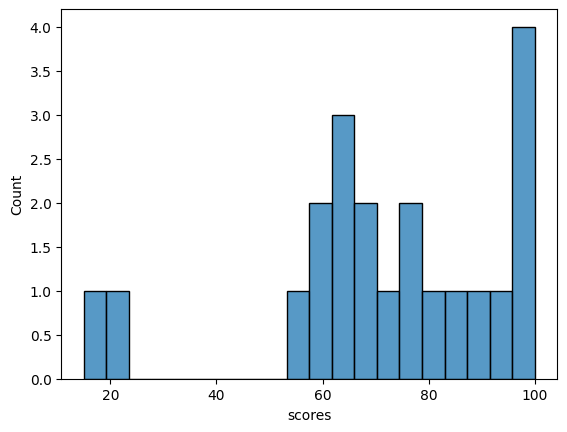

<Axes: xlabel='scores', ylabel='Density'>

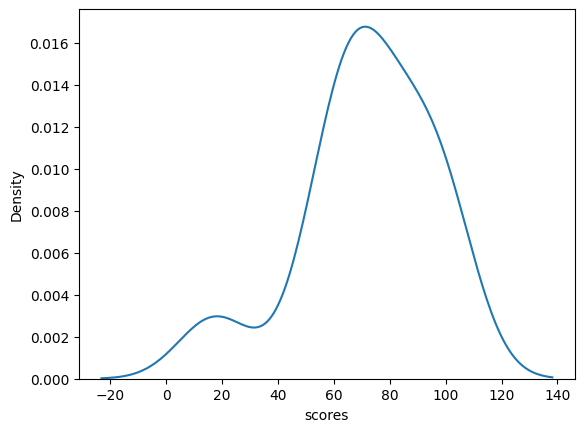

In [244]:
df1 = pd.DataFrame(
    { 'scores' : [55, 58, 60, 62, 65, 65, 68, 70, 72, 75, 78, 80, 85, 90, 95, 98, 100, 100, 100, 15, 20] }
)

df2 = pd.DataFrame(
    { 'prices' : [30, 32, 35, 38, 40, 42, 45, 48, 50, 55, 60, 65, 70, 80, 90, 100, 120, 150, 200, 300, 400, 500, 800, 1000, 1200] }
)

df1
df2

sns.histplot(data = df1, x = 'scores', bins = 20)

plt.show()

sns.kdeplot(data = df1, x = 'scores')

In [245]:
# From the histogram we can observe that, the data is left skewed.

# Rule: If skewness is negative, it's Left-Skewed. If positive, it's Right-Skewed.

print(f"Skewness value: {df1['scores'].skew():.2f}")

# Preferred method is IQR. Because the dataset is not normal and contain extreme values.

Skewness value: -1.00


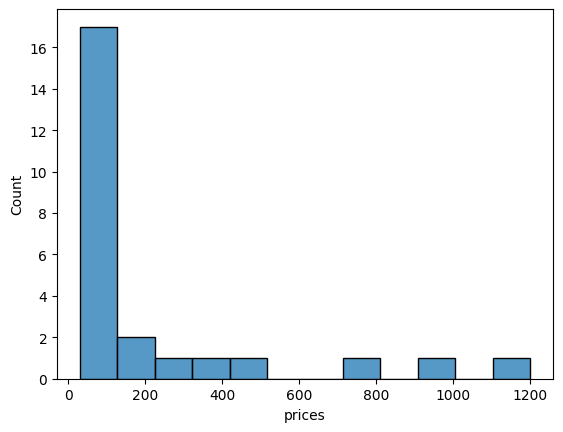

<Axes: xlabel='prices', ylabel='Density'>

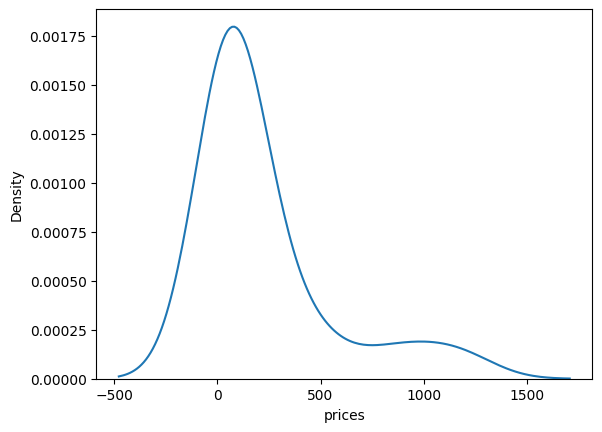

In [246]:
# Dataset B
df2

sns.histplot(data = df2, x = df2['prices'])
plt.show()

sns.kdeplot(data = df2, x = df2['prices'])

In [247]:
print(f"Skewness value: {df2['prices'].skew():.2f}")

Skewness value: 2.11


In [248]:
# We will use IQR method for the dataset B. Because the dataset is positively skewed

prices_Q1 = df2['prices'].quantile(0.25)
prices_Q3 = df2['prices'].quantile(0.75)

prices_Q1
prices_Q3

prices_IQR = prices_Q3 - prices_Q1

prices_IQR

prices_min = prices_Q1 - ( 1.5 * prices_IQR )
prices_max = prices_Q3 + ( 1.5 * prices_IQR )

print(prices_min, prices_max)

prices_outlier_IQR = df2[ ( df2['prices'] < prices_min ) | ( df2['prices'] > prices_max ) ]

print('Outliers : \n')
display(prices_outlier_IQR)

print(f'Total outliers : {len(prices_outlier_IQR)}')


-187.5 432.5
Outliers : 



,prices
21,500
22,800
23,1000
24,1200


Total outliers : 4


Problem 4: Winsorization (Percentile Method)

Dataset (Product ratings out of 10):

[1, 2, 3, 4, 4, 5, 5, 5, 6, 6, 7, 7, 8, 8, 9, 9, 10, 10, 1, 2, 10, 10, 10, 0.5, 9.5]

Tasks:

Use 5% Winsorization (x = 5, meaning cap at 5th and 95th percentiles).

Calculate 5th percentile and 95th percentile.

Cap all values below 5th percentile to the 5th percentile value.

Cap all values above 95th percentile to the 95th percentile value.

Show the min and max after Winsorization.

Explain why Winsorization is better than deletion here.


In [249]:
df = pd.DataFrame(
    { 'ratings' : [1, 2, 3, 4, 4, 5, 5, 5, 6, 6, 7, 7, 8, 8, 9, 9, 10, 10, 1, 2, 10, 10, 10, 0.5, 9.5] }
)

df

,ratings
0,1.0
1,2.0
2,3.0
3,4.0
4,4.0
5,5.0
6,5.0
7,5.0
8,6.0
9,6.0


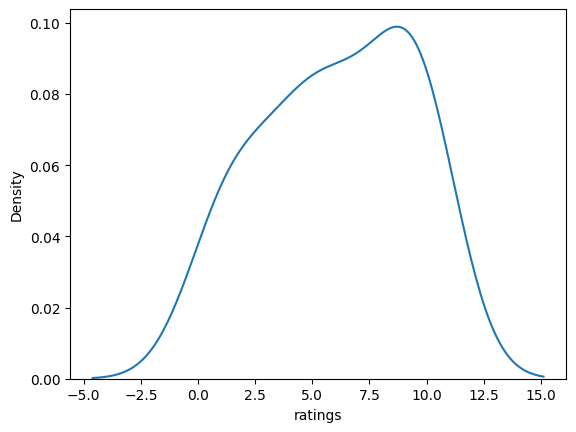

In [250]:
sns.kdeplot( data = df, x = 'ratings' )

plt.show()

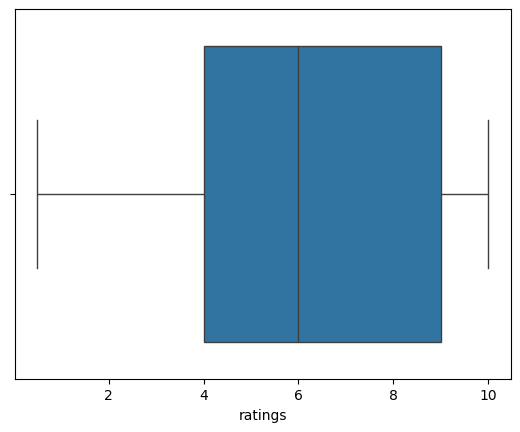

In [251]:
sns.boxplot( data = df, x = 'ratings' )

plt.show()

In [252]:
df.describe()

,ratings
count,25.000000
mean,6.080000
std,3.242556
min,0.500000
25%,4.000000
50%,6.000000
75%,9.000000
max,10.000000


In [253]:
x = 5
x = x / 100

min_range = df['ratings'].quantile(x)
max_range = df['ratings'].quantile(1 - x)

print(f'Min range : {min_range} and Max range : {max_range}')


df['winsorized'] = np.where(
    df['ratings'] < min_range,
    min_range,
    np.where(df['ratings'] > max_range, max_range, df['ratings'])
)

Min range : 1.0 and Max range : 10.0


In [254]:
print(f"After Winsorization: \n{df}")

After Winsorization: 
    ratings  winsorized
0       1.0         1.0
1       2.0         2.0
2       3.0         3.0
3       4.0         4.0
4       4.0         4.0
5       5.0         5.0
6       5.0         5.0
7       5.0         5.0
8       6.0         6.0
9       6.0         6.0
10      7.0         7.0
11      7.0         7.0
12      8.0         8.0
13      8.0         8.0
14      9.0         9.0
15      9.0         9.0
16     10.0        10.0
17     10.0        10.0
18      1.0         1.0
19      2.0         2.0
20     10.0        10.0
21     10.0        10.0
22     10.0        10.0
23      0.5         1.0
24      9.5         9.5


In [255]:
print(f'Max Value After Winsorized : {df['winsorized'].max()}')

print(f'Min Value After Winsorized : {df['winsorized'].min()}')

Max Value After Winsorized : 10.0
Min Value After Winsorized : 1.0


Winsorization is better than deletion here because it preserves all observations while reducing the effect of extreme values. In this dataset, the extreme ratings (very low and very high values) are still valid data points rather than errors, so removing them would lead to loss of important information. Since the dataset is small, deletion would further reduce the sample size and make the analysis less reliable. Winsorization, on the other hand, keeps the dataset size unchanged and only caps extreme values, resulting in a more stable and realistic representation of the data.

# Extra (Optional)

Problem 5: Mixed Methods – Compare Z-Score & IQR on Same Data
Dataset (Product ratings out of 10):

[12, 15, 18, 20, 22, 22, 23, 24, 25, 25, 26, 27, 28, 30, 32, 35, 38, 40, 45, 50, 55, 60, 65, 70, 80, 90, 100, 120, 150, 200, 500, 1000, 2000]


Tasks:

Plot a histogram (conceptually) and decide if the data is normal or skewed.

Apply Z-Score method (|Z| > 3) – count outliers and list them.

Apply IQR method (1.5×IQR) – count outliers and list them.

Which method found more outliers? Why?

Which method would you trust here? Justify.


In [256]:
df = pd.DataFrame(
    { 'data' : [12, 15, 18, 20, 22, 22, 23, 24, 25, 25, 26, 27, 28, 30, 32, 35, 38, 40, 45, 50, 55, 60, 65, 70, 80, 90, 100, 120, 150, 200, 500, 1000, 2000] }
)

df

,data
0,12
1,15
2,18
3,20
4,22
5,22
6,23
7,24
8,25
9,25


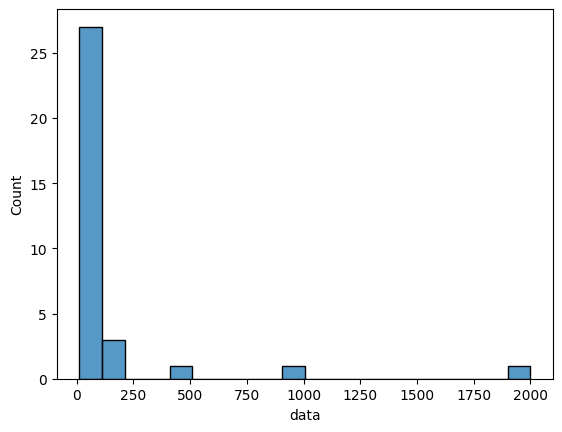

In [257]:
sns.histplot( data = df, x = df['data'], bins = 20 )

plt.show()

<Axes: xlabel='data', ylabel='Density'>

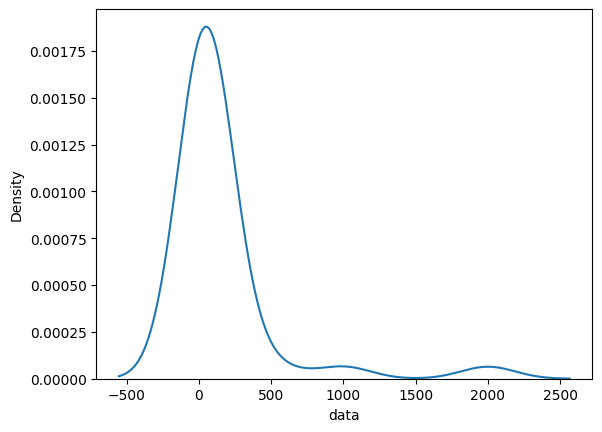

In [258]:
sns.kdeplot( data = df, x = df['data'] )

In [259]:
print(f'Skewness : {df['data'].skew():.2f}')

Skewness : 4.20


In [260]:
# We can see the data is highly right-skewed.

# Using Z-score

mean_of_data = df['data'].mean()
std_of_data = df['data'].std()

df['zscore_data'] = ( df['data'] - mean_of_data ) / std_of_data

df

outlier = df[abs( df['zscore_data'] ) > 3]

print(len(outlier))
display(outlier)


1


,data,zscore_data
32,2000,4.865011


In [261]:
# Using IQR

Q1 = df['data'].quantile(0.25)
Q3 = df['data'].quantile(0.75)

IQR = Q3 - Q1

lower_bound  = Q1 - ( 1.5 * IQR )
upper_bound  = Q3 + ( 1.5 * IQR )

print(lower_bound, upper_bound)

outlier = df[ ( df['data'] < lower_bound ) | ( df['data'] > upper_bound  ) ]

print(len(outlier))
display(outlier)

-57.5 162.5
4


,data,zscore_data
29,200,0.123954
30,500,0.914130
31,1000,2.231090
32,2000,4.865011


In this dataset, the IQR method finds more outliers than the Z-score method.

Reason :


*   The dataset is highly right-skewed
*   It contains very large extreme values (500, 1000, 2000)
*   These extreme values heavily affect the mean and standard deviation

So:


*   Z-score becomes “less sensitive” because the standard deviation increases a lot
*   IQR remains stable because it depends on median and quartiles

Therefore, IQR tends to detect more (or more reliable) outliers in skewed data.



##### The IQR method is based on median and quartiles, which are not affected by extreme values. Therefore, the IQR method is more reliable and trustworthy for this dataset.

### Problem 6: Real-World Scenario – Employee Bonus
Scenario:

A company gives an annual bonus (in thousand BDT). HR wants to remove extreme outliers before calculating average bonus for policy making.

Dataset (Bonus amounts):
[5, 5, 6, 6, 7, 7, 7, 8, 8, 8, 9, 9, 10, 10, 10, 11, 12, 13, 15, 18, 20, 25, 30, 35, 40, 50, 60, 80, 100, 120, 150, 200, 300]


Tasks:

Calculate mean, median, and mode. What do you observe?

Apply IQR method and find outliers.

Instead of deleting, apply Winsorization with x = 3 (i.e., cap at 3rd and 97th percentile).

Show the new min and max after Winsorization.

Calculate the new mean after Winsorization. Is it more reasonable than the original mean?


In [262]:
df = pd.DataFrame(
    { 'bonus' : [5, 5, 6, 6, 7, 7, 7, 8, 8, 8, 9, 9, 10, 10, 10, 11, 12, 13, 15, 18, 20, 25, 30, 35, 40, 50, 60, 80, 100, 120, 150, 200, 300] }
)

df

,bonus
0,5
1,5
2,6
3,6
4,7
5,7
6,7
7,8
8,8
9,8


In [270]:
print(f'Mean : {df['bonus'].mean()}')
print(f'Median : {df['bonus'].median()}')
print(f'Mode : \n{df['bonus'].mode()}')

Mean : 42.24242424242424
Median : 12.0
Mode : 
0     7
1     8
2    10
Name: bonus, dtype: int64


Here,

*   Mean is affected by extreme values (200, 300)
*   Median is stable
*   Mode shows most common bonus values (7, 8, 10)

Also, Mean > Meddian. That means the data is right-skewed.


In [271]:
# IQR

Q1 = df['bonus'].quantile(0.25)
Q3 = df['bonus'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - ( 1.5 * IQR )
upper_bound = Q3 + ( 1.5 * IQR )

outlier = df[ ( df['bonus'] < lower_bound ) | ( df['bonus'] > upper_bound ) ]

print(len(outlier))
display(outlier)


5


,bonus
28,100
29,120
30,150
31,200
32,300


In [275]:
# Winsorization

x = 3
x = 3 / 100

min_range = df['bonus'].quantile(x)
max_range = df['bonus'].quantile(1 - x)

print(f'Min range : {min_range} and Max range : {max_range}')

df['bonus'] = df['bonus'].clip(min_range, max_range)
df

df['bonus'].mean()

Min range : 5.0 and Max range : 200.0064


np.float64(39.21231515151515)



*   The original mean is heavily affected by extreme bonus amounts like 200 and 300.
*   Winsorization caps those extreme values instead of deleting them.

*   The new mean becomes more stable and realistic.
*   Therefore, the Winsorized mean is more reasonable for HR

*   policy-making because it better represents the typical employee bonus distribution.






